In [1]:
# ── IMPORTS ──────────────────────────────────────────────────────────────
# Load core libraries for data manipulation and visualisation

import numpy as np
import pandas as pd
import plotly.io as pio
pio.renderers.default = "browser"

In [3]:
# ── LOAD DATA ────────────────────────────────────────────────────────────
# Read the raw NACA 4-series aerofoil dataset
# Each row = one aerofoil at one Reynolds number at one angle of attack
df = pd.read_csv("../data/naca4series_24_airfoils.csv")
df.head()

,airfoilName,maxCamber,maxCamberXloc,maxThickness,reynoldsNumber,angleOfAttack,liftCoefficient,dragCoefficient
0,naca0006,0.0,0.0,0.06,50000,-8.25,-0.6744,0.10463
1,naca0006,0.0,0.0,0.06,50000,-8.00,-0.6770,0.10152
2,naca0006,0.0,0.0,0.06,50000,-7.75,-0.6873,0.09891
3,naca0006,0.0,0.0,0.06,50000,-7.50,-0.6648,0.09391
4,naca0006,0.0,0.0,0.06,50000,-7.00,-0.6541,0.08634


In [4]:
# ── SANITY CHECK ─────────────────────────────────────────────────────────
# Confirm shape, missing values, unique aerofoils, Reynolds values, and AoA range
print("Shape:", df.shape)
print("Missing values:\n", df.isna().sum())
print("Unique airfoils:", df["airfoilName"].nunique())
print("Reynolds values:", sorted(df["reynoldsNumber"].unique()))
print("AoA range:", df["angleOfAttack"].min(), "to", df["angleOfAttack"].max())

Shape: (16500, 8)
Missing values:
 airfoilName        0
maxCamber          0
maxCamberXloc      0
maxThickness       0
reynoldsNumber     0
angleOfAttack      0
liftCoefficient    0
dragCoefficient    0
dtype: int64
Unique airfoils: 24
Reynolds values: [np.int64(50000), np.int64(100000), np.int64(200000), np.int64(500000), np.int64(1000000)]
AoA range: -19.75 to 19.25


In [5]:
# ── FEATURE ENGINEERING (1/2) ────────────────────────────────────────────
# Derive lift-to-drag ratio (L/D) — key efficiency metric
# Replaces zero drag values with NaN to avoid division errors
df = df.copy()
df["L_over_D"] = df["liftCoefficient"] / df["dragCoefficient"].replace(0, np.nan)
df[["airfoilName","reynoldsNumber","angleOfAttack","liftCoefficient","dragCoefficient","L_over_D"]].head()

,airfoilName,reynoldsNumber,angleOfAttack,liftCoefficient,dragCoefficient,L_over_D
0,naca0006,50000,-8.25,-0.6744,0.10463,-6.445570
1,naca0006,50000,-8.00,-0.6770,0.10152,-6.668637
2,naca0006,50000,-7.75,-0.6873,0.09891,-6.948741
3,naca0006,50000,-7.50,-0.6648,0.09391,-7.079118
4,naca0006,50000,-7.00,-0.6541,0.08634,-7.575863


In [6]:
# ── FEATURE ENGINEERING (2/2) ────────────────────────────────────────────
# Collapse from one row per operating point to one row per (aerofoil, Reynolds number)
# Aggregates: geometry (static), lift stats, drag stats, and L/D stats across all AoA
summary = (
    df.groupby(["airfoilName", "reynoldsNumber"], as_index=False)
      .agg(
          # geomtry (static)
          maxCamber=("maxCamber", "first"),
          maxCamberXloc=("maxCamberXloc", "first"),
          maxThickness=("maxThickness", "first"),

          # lift across AoAthe small
          Cl_mean=("liftCoefficient", "mean"),
          Cl_max=("liftCoefficient", "max"),
          Cl_min=("liftCoefficient", "min"),

          # drag across AoA
          Cd_mean=("dragCoefficient", "mean"),
          Cd_min=("dragCoefficient", "min"),
          Cd_max=("dragCoefficient", "max"),

          # efficiency across AoA
          L_over_D_mean=("L_over_D", "mean"),
          L_over_D_max=("L_over_D", "max"),
      )
)

summary.head()

,airfoilName,reynoldsNumber,maxCamber,maxCamberXloc,maxThickness,Cl_mean,Cl_max,Cl_min,Cd_mean,Cd_min,Cd_max,L_over_D_mean,L_over_D_max
0,naca0006,50000,0.0,0.0,0.06,-0.020810,0.6872,-0.6873,0.037056,0.01416,0.10464,-0.254207,24.899083
1,naca0006,100000,0.0,0.0,0.06,-0.033349,0.7210,-0.7208,0.044088,0.01012,0.11447,-0.575375,32.855848
2,naca0006,200000,0.0,0.0,0.06,0.013888,0.7075,-0.7058,0.027826,0.00728,0.09692,0.192475,38.905852
3,naca0006,1000000,0.0,0.0,0.06,-0.045487,0.7383,-0.7533,0.017964,0.00338,0.12546,-0.958400,56.628702
4,naca0008,50000,0.0,0.0,0.08,-0.018613,0.7444,-0.7443,0.032016,0.01541,0.10317,-0.119645,26.123009


In [7]:
# ── FEATURE ENGINEERING — OPTIMAL AoA ───────────────────────────────────
# Find the angle of attack at which each aerofoil achieves maximum L/D and maximum Cl
# These are operationally meaningful — not just statistical summaries

# AoA at maximum L/D for each (airfoil, Re)
idx_ld = df.groupby(["airfoilName", "reynoldsNumber"])["L_over_D"].idxmax()
best_ld = df.loc[idx_ld, ["airfoilName","reynoldsNumber","angleOfAttack","L_over_D"]]
best_ld = best_ld.rename(columns={"angleOfAttack":"AoA_at_LD_max"})

# AoA at maximum Cl for each (airfoil, Re)
idx_cl = df.groupby(["airfoilName", "reynoldsNumber"])["liftCoefficient"].idxmax()
best_cl = df.loc[idx_cl, ["airfoilName","reynoldsNumber","angleOfAttack","liftCoefficient"]]
best_cl = best_cl.rename(columns={"angleOfAttack":"AoA_at_Cl_max", "liftCoefficient":"Cl_max_check"})

# merge
summary2 = summary.merge(best_ld, on=["airfoilName","reynoldsNumber"], how="left") \
                  .merge(best_cl, on=["airfoilName","reynoldsNumber"], how="left")

summary2.head()

,airfoilName,reynoldsNumber,maxCamber,maxCamberXloc,maxThickness,Cl_mean,Cl_max,Cl_min,Cd_mean,Cd_min,Cd_max,L_over_D_mean,L_over_D_max,AoA_at_LD_max,L_over_D,AoA_at_Cl_max,Cl_max_check
0,naca0006,50000,0.0,0.0,0.06,-0.020810,0.6872,-0.6873,0.037056,0.01416,0.10464,-0.254207,24.899083,3.5,24.899083,7.75,0.6872
1,naca0006,100000,0.0,0.0,0.06,-0.033349,0.7210,-0.7208,0.044088,0.01012,0.11447,-0.575375,32.855848,3.0,32.855848,8.50,0.7210
2,naca0006,200000,0.0,0.0,0.06,0.013888,0.7075,-0.7058,0.027826,0.00728,0.09692,0.192475,38.905852,2.5,38.905852,8.00,0.7075
3,naca0006,1000000,0.0,0.0,0.06,-0.045487,0.7383,-0.7533,0.017964,0.00338,0.12546,-0.958400,56.628702,4.5,56.628702,7.25,0.7383
4,naca0008,50000,0.0,0.0,0.08,-0.018613,0.7444,-0.7443,0.032016,0.01541,0.10317,-0.119645,26.123009,4.0,26.123009,7.50,0.7444


In [8]:
# ── REDUCED DATASET — OVERVIEW ───────────────────────────────────────────
# Confirm reduced shape: 119 rows (one per aerofoil per Reynolds number)
# Each row now represents the full aerodynamic character of one aerofoil at one Re
print("Reduced shape:", summary2.shape)
summary2.describe(include="all")

Reduced shape: (119, 17)


,airfoilName,reynoldsNumber,maxCamber,maxCamberXloc,maxThickness,Cl_mean,Cl_max,Cl_min,Cd_mean,Cd_min,Cd_max,L_over_D_mean,L_over_D_max,AoA_at_LD_max,L_over_D,AoA_at_Cl_max,Cl_max_check
count,119,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000
unique,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,naca0008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,368907.563025,0.018908,0.285714,0.147815,0.215512,1.201526,-0.920791,0.034024,0.015088,0.111574,11.018824,57.701058,6.296218,57.701058,12.970588,1.201526
std,NaN,354331.047727,0.016712,0.181466,0.055068,0.244856,0.299251,0.271671,0.015402,0.011723,0.025064,12.443636,28.830131,2.096447,28.830131,3.622724,0.299251
min,NaN,50000.000000,0.000000,0.000000,0.060000,-0.332020,0.229700,-1.400500,0.017964,0.003380,0.072750,-6.202251,1.759210,2.000000,1.759210,4.500000,0.229700
25%,NaN,100000.000000,0.000000,0.000000,0.100000,0.000095,1.032250,-1.150300,0.023938,0.007615,0.091765,0.001993,36.704298,4.750000,36.704298,9.750000,1.032250
50%,NaN,200000.000000,0.020000,0.400000,0.150000,0.202314,1.262400,-0.943400,0.029607,0.010820,0.106280,8.643564,55.200422,6.000000,55.200422,13.250000,1.262400
75%,NaN,500000.000000,0.030000,0.400000,0.195000,0.352181,1.402450,-0.706400,0.036977,0.017610,0.126580,18.797964,75.124906,7.750000,75.124906,16.250000,1.402450


In [9]:
# ── EXPORT ───────────────────────────────────────────────────────────────
# Save the reduced summary dataset to CSV and Excel for external use
summary2.to_csv("../outputs/airfoil_summary_per_Re.csv", index=False)
summary2.to_excel("../outputs/airfoil_summary_per_Re.xlsx", index=False)
print("Saved: airfoil_summary_per_Re.csv and airfoil_summary_per_Re.xlsx")

Saved: airfoil_summary_per_Re.csv and airfoil_summary_per_Re.xlsx


In [10]:
summary2.describe()

,reynoldsNumber,maxCamber,maxCamberXloc,maxThickness,Cl_mean,Cl_max,Cl_min,Cd_mean,Cd_min,Cd_max,L_over_D_mean,L_over_D_max,AoA_at_LD_max,L_over_D,AoA_at_Cl_max,Cl_max_check
count,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000
mean,368907.563025,0.018908,0.285714,0.147815,0.215512,1.201526,-0.920791,0.034024,0.015088,0.111574,11.018824,57.701058,6.296218,57.701058,12.970588,1.201526
std,354331.047727,0.016712,0.181466,0.055068,0.244856,0.299251,0.271671,0.015402,0.011723,0.025064,12.443636,28.830131,2.096447,28.830131,3.622724,0.299251
min,50000.000000,0.000000,0.000000,0.060000,-0.332020,0.229700,-1.400500,0.017964,0.003380,0.072750,-6.202251,1.759210,2.000000,1.759210,4.500000,0.229700
25%,100000.000000,0.000000,0.000000,0.100000,0.000095,1.032250,-1.150300,0.023938,0.007615,0.091765,0.001993,36.704298,4.750000,36.704298,9.750000,1.032250
50%,200000.000000,0.020000,0.400000,0.150000,0.202314,1.262400,-0.943400,0.029607,0.010820,0.106280,8.643564,55.200422,6.000000,55.200422,13.250000,1.262400
75%,500000.000000,0.030000,0.400000,0.195000,0.352181,1.402450,-0.706400,0.036977,0.017610,0.126580,18.797964,75.124906,7.750000,75.124906,16.250000,1.402450
max,1000000.000000,0.060000,0.400000,0.240000,0.932986,1.708400,-0.166800,0.088653,0.059420,0.195610,57.408234,142.652608,10.750000,142.652608,19.250000,1.708400


In [11]:
# ── EDA (1/2) — REYNOLDS vs L/D ─────────────────────────────────────────
# Explore how mean peak L/D varies across Reynolds numbers
# Key insight: L/D improves consistently as Re increases
summary2.groupby("reynoldsNumber")["L_over_D_max"].mean()

reynoldsNumber
50000      20.706847
100000     42.654753
200000     58.293463
500000     77.299374
1000000    90.367451
Name: L_over_D_max, dtype: float64

In [12]:
# ── EDA (2/2) — THICKNESS vs LIFT ───────────────────────────────────────
# Explore how mean max lift coefficient varies with aerofoil thickness
summary2.groupby("maxThickness")["Cl_max"].mean()

maxThickness
0.06    0.713500
0.08    1.022473
0.10    1.167560
0.11    1.331220
0.12    1.393870
0.15    1.287700
0.18    1.251220
0.21    1.219280
0.24    1.091373
Name: Cl_max, dtype: float64

In [13]:
# ── FEATURE SELECTION ────────────────────────────────────────────────────
# Select the 8 features used for clustering:
# 3 geometry descriptors + 4 performance descriptors + Reynolds number
features = summary2[[
    "maxCamber",
    "maxCamberXloc",
    "maxThickness",
    "reynoldsNumber",
    "Cl_max",
    "Cd_min",
    "L_over_D_max",
    "AoA_at_LD_max"
]]

features.head()

,maxCamber,maxCamberXloc,maxThickness,reynoldsNumber,Cl_max,Cd_min,L_over_D_max,AoA_at_LD_max
0,0.0,0.0,0.06,50000,0.6872,0.01416,24.899083,3.5
1,0.0,0.0,0.06,100000,0.7210,0.01012,32.855848,3.0
2,0.0,0.0,0.06,200000,0.7075,0.00728,38.905852,2.5
3,0.0,0.0,0.06,1000000,0.7383,0.00338,56.628702,4.5
4,0.0,0.0,0.08,50000,0.7444,0.01541,26.123009,4.0


In [14]:
# ── PREPROCESSING — STANDARDISATION ─────────────────────────────────────
# Apply StandardScaler: transforms each feature to mean=0, std=1
# Prevents Reynolds number (100k–1M) from dominating distance calculations

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# Each feature now has mean ≈ 0 and std ≈ 1
# Reynolds number no longer dominates the space

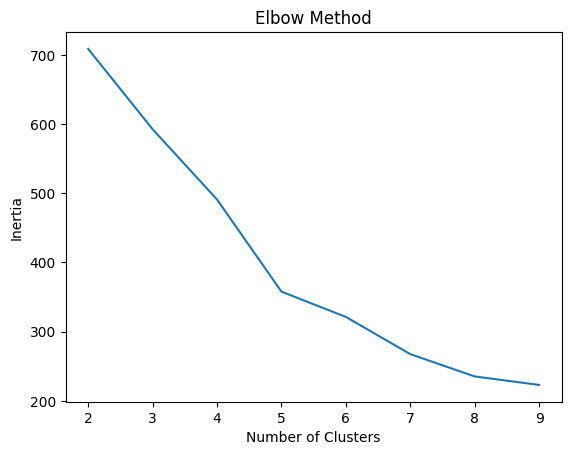

In [15]:
# ── CLUSTERING — ELBOW METHOD ────────────────────────────────────────────
# Sweep k=2..9, plot inertia to identify the elbow point
# Helps select a sensible k before running final KMeans

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 10), inertia)
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [16]:
kmeans = KMeans(n_clusters=7, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

summary2["cluster"] = clusters

In [17]:
summary2.groupby("cluster").mean(numeric_only=True)

,reynoldsNumber,maxCamber,maxCamberXloc,maxThickness,Cl_mean,Cl_max,Cl_min,Cd_mean,Cd_min,Cd_max,L_over_D_mean,L_over_D_max,AoA_at_LD_max,L_over_D,AoA_at_Cl_max,Cl_max_check
cluster,,,,,,,,,,,,,,,,
0,55555.555556,0.035556,0.4,0.196667,-0.079392,0.577867,-0.761511,0.074427,0.044869,0.130240,-2.212446,8.455675,6.694444,8.455675,9.222222,0.577867
1,826086.956522,0.028261,0.4,0.133913,0.381887,1.501957,-1.053839,0.022827,0.006463,0.104628,25.028867,100.101884,5.163043,100.101884,15.434783,1.501957
2,800000.000000,0.000000,0.0,0.174000,0.015154,1.306410,-1.258730,0.023674,0.007373,0.094186,1.861859,68.273168,9.025000,68.273168,16.550000,1.306410
3,267857.142857,0.032143,0.4,0.185357,0.396674,1.383693,-0.908571,0.033985,0.015990,0.109139,15.552669,57.402408,7.857143,57.402408,15.080357,1.383693
4,254166.666667,0.000000,0.0,0.080000,-0.010564,0.832092,-0.833217,0.030927,0.009984,0.113014,-0.046482,39.563973,3.687500,39.563973,8.375000,0.832092
5,116666.666667,0.000000,0.0,0.195000,-0.002670,1.084983,-1.085108,0.040554,0.024198,0.112225,-0.028326,34.850889,6.875000,34.850889,12.437500,1.084983
6,178000.000000,0.015200,0.4,0.100400,0.259097,1.136936,-0.697400,0.032314,0.012456,0.119924,12.091701,52.200164,5.330000,52.200164,10.720000,1.136936


In [18]:
# ── PREPROCESSING — STANDARDISATION ─────────────────────────────────────
# Apply StandardScaler: transforms each feature to mean=0, std=1
# Prevents Reynolds number from dominating distance calculations
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [19]:
# ── DIMENSIONALITY REDUCTION — PCA ──────────────────────────────────────
# Reduce to 3 components for 3D visualisation
# Linear method — projects onto directions of maximum variance
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance captured:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.395813   0.26026512 0.18054548]
Total variance captured: 0.8366236003287344


In [20]:
# ── DIMENSIONALITY REDUCTION — t-SNE ────────────────────────────────────
# Non-linear reduction to 2D
# Preserves local neighbourhood relationships — reveals tight cluster groupings
# Non-deterministic; global distances are not meaningful
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=10)
X_tsne = tsne.fit_transform(X_scaled)

In [21]:
# ── DIMENSIONALITY REDUCTION — UMAP ─────────────────────────────────────
# Non-linear reduction to 2D
# Balances local and global structure — more stable than t-SNE
# Primary visualisation tool
import umap.umap_ as umap

reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)


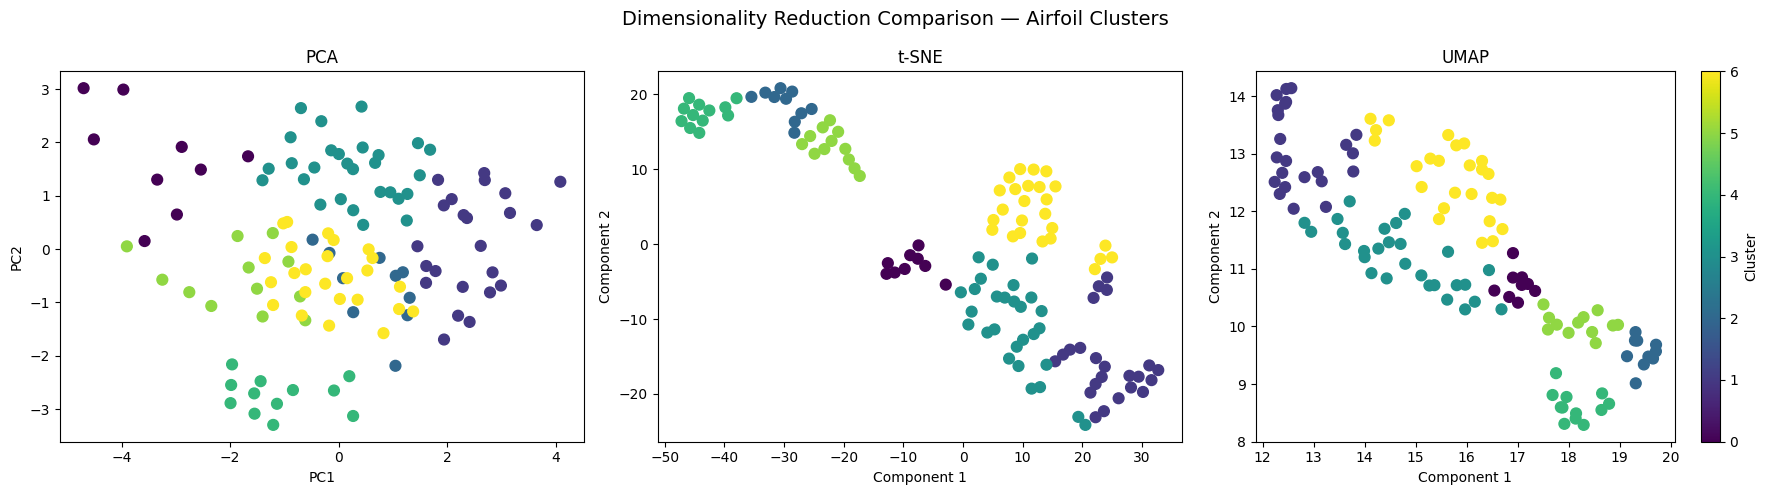

In [22]:
# ── VISUALISATION — PCA / t-SNE / UMAP COMPARISON ───────────────────────
# Side-by-side scatter plots of all three techniques, coloured by KMeans cluster
# Key takeaway: t-SNE and UMAP reveal separation that PCA misses entirely

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# PCA
sc0 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=summary2["cluster"], cmap="viridis", s=60)
axes[0].set_title("PCA")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# t-SNE
sc1 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=summary2["cluster"], cmap="viridis", s=60)
axes[1].set_title("t-SNE")
axes[1].set_xlabel("Component 1")
axes[1].set_ylabel("Component 2")

# UMAP
sc2 = axes[2].scatter(X_umap[:, 0], X_umap[:, 1], c=summary2["cluster"], cmap="viridis", s=60)
axes[2].set_title("UMAP")
axes[2].set_xlabel("Component 1")
axes[2].set_ylabel("Component 2")

fig.colorbar(sc2, ax=axes[2], label="Cluster")
fig.suptitle("Dimensionality Reduction Comparison — Airfoil Clusters", fontsize=14)
plt.tight_layout()
plt.savefig("../docs/images/naca_dim_reduction_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

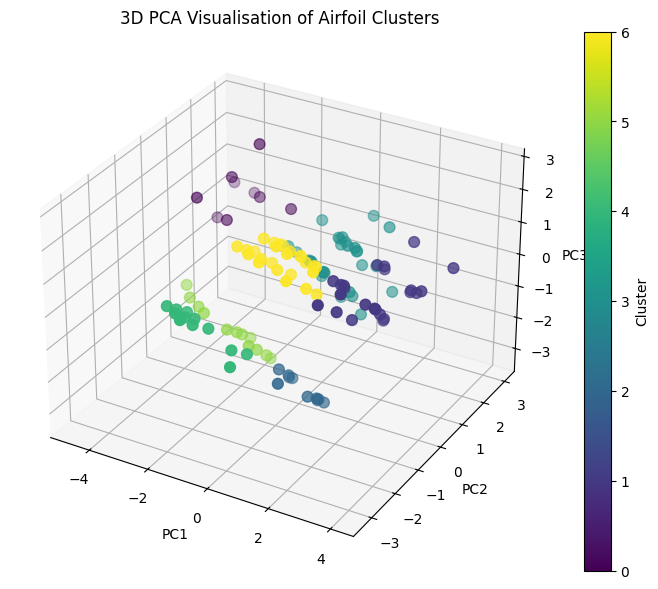

In [23]:
# ── VISUALISATION — PCA 3D (matplotlib) ─────────────────────────────────
# Static 3D scatter of PCA projection coloured by cluster
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca[:,0],
    X_pca[:,1],
    X_pca[:,2],
    c=summary2["cluster"],
    cmap="viridis",
    s=60
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D PCA Visualisation of Airfoil Clusters")

fig.colorbar(scatter, label="Cluster")
plt.show()

In [24]:
import plotly.express as px

pca_df = pd.DataFrame({
    "PC1": X_pca[:,0],
    "PC2": X_pca[:,1],
    "PC3": X_pca[:,2],
    "cluster": summary2["cluster"],
    "airfoil": summary2["airfoilName"],
    "Re": summary2["reynoldsNumber"],
    "thickness": summary2["maxThickness"],
    "L_over_D_max": summary2["L_over_D_max"]
})

fig = px.scatter_3d(
    pca_df,
    x="PC1",
    y="PC2",
    z="PC3",
    color="cluster",
    hover_data={
        "airfoil": True,
        "Re": True,
        "thickness": True,
        "L_over_D_max": True
    }
)

fig.show()

In [25]:
from sklearn.metrics import silhouette_score
score = silhouette_score(X_scaled, summary2["cluster"])
print(score)

0.3316347819611977


In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k = {k}, silhouette = {score:.3f}")

k = 2, silhouette = 0.226
k = 3, silhouette = 0.239
k = 4, silhouette = 0.237
k = 5, silhouette = 0.297
k = 6, silhouette = 0.301
k = 7, silhouette = 0.332
k = 8, silhouette = 0.329
k = 9, silhouette = 0.312


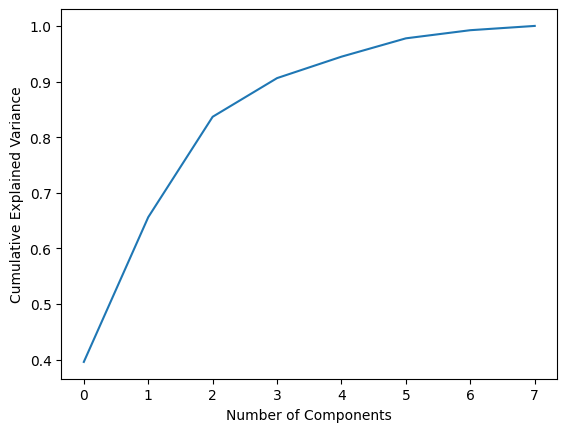

In [27]:
pca_full = PCA()
pca_full.fit(X_scaled)

plt.plot(np.cumsum(pca_full.explained_variance_ratio_))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()

In [28]:
loadings = pd.DataFrame(
    pca.components_,
    columns=features.columns,
    index=["PC1", "PC2", "PC3"]
)
loadings

,maxCamber,maxCamberXloc,maxThickness,reynoldsNumber,Cl_max,Cd_min,L_over_D_max,AoA_at_LD_max
PC1,0.148880,0.171039,-0.109456,0.439512,0.481948,-0.457370,0.545603,-0.065460
PC2,0.540264,0.415871,0.447277,-0.079802,0.199681,0.305027,0.008620,0.442440
PC3,0.373359,0.531706,-0.485100,-0.253959,-0.140219,0.078421,-0.031843,-0.501248


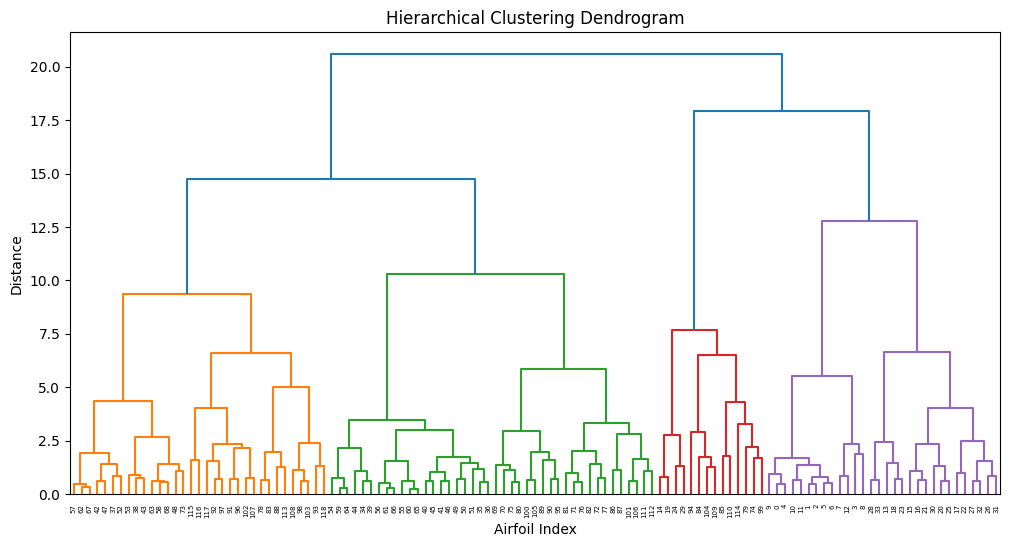

In [29]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Ward method works best for Euclidean spaces
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12,6))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Airfoil Index")
plt.ylabel("Distance")
plt.show()

In [30]:
from scipy.cluster.hierarchy import fcluster

hier_labels = fcluster(Z, 5, criterion='maxclust')
summary2["hier_cluster"] = hier_labels

In [31]:
summary2[["cluster","hier_cluster"]].head()

,cluster,hier_cluster
0,4,4
1,4,4
2,4,4
3,4,4
4,4,4


In [32]:
import pandas as pd

pd.crosstab(summary2["cluster"], summary2["hier_cluster"])

hier_cluster,1,2,3,4,5
cluster,,,,,
0,0,0,9,0,0
1,22,1,0,0,0
2,0,0,0,1,9
3,7,20,1,0,0
4,0,0,0,12,0
5,0,0,4,0,8
6,4,21,0,0,0


In [33]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np

for eps in np.arange(0.5, 2.5, 0.2):
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)

    if n_clusters > 1:
        score = silhouette_score(X_scaled, labels)
        print(f"eps={eps:.2f} | clusters={n_clusters} | noise={n_noise} | silhouette={score:.3f}")
    else:
        print(f"eps={eps:.2f} | clusters={n_clusters} | noise={n_noise}")

eps=0.50 | clusters=0 | noise=119
eps=0.70 | clusters=1 | noise=112
eps=0.90 | clusters=3 | noise=79 | silhouette=-0.001
eps=1.10 | clusters=5 | noise=62 | silhouette=0.044
eps=1.30 | clusters=4 | noise=35 | silhouette=0.139
eps=1.50 | clusters=4 | noise=21 | silhouette=0.203
eps=1.70 | clusters=2 | noise=11 | silhouette=0.294
eps=1.90 | clusters=2 | noise=9 | silhouette=0.301
eps=2.10 | clusters=2 | noise=9 | silhouette=0.301
eps=2.30 | clusters=3 | noise=3 | silhouette=0.289


In [34]:
dbscan = DBSCAN(eps=1.7, min_samples=5)
db_labels = dbscan.fit_predict(X_scaled)

summary2["dbscan_cluster"] = db_labels

In [35]:
summary2.head()

,airfoilName,reynoldsNumber,maxCamber,maxCamberXloc,maxThickness,Cl_mean,Cl_max,Cl_min,Cd_mean,Cd_min,Cd_max,L_over_D_mean,L_over_D_max,AoA_at_LD_max,L_over_D,AoA_at_Cl_max,Cl_max_check,cluster,hier_cluster,dbscan_cluster
0,naca0006,50000,0.0,0.0,0.06,-0.020810,0.6872,-0.6873,0.037056,0.01416,0.10464,-0.254207,24.899083,3.5,24.899083,7.75,0.6872,4,4,0
1,naca0006,100000,0.0,0.0,0.06,-0.033349,0.7210,-0.7208,0.044088,0.01012,0.11447,-0.575375,32.855848,3.0,32.855848,8.50,0.7210,4,4,0
2,naca0006,200000,0.0,0.0,0.06,0.013888,0.7075,-0.7058,0.027826,0.00728,0.09692,0.192475,38.905852,2.5,38.905852,8.00,0.7075,4,4,0
3,naca0006,1000000,0.0,0.0,0.06,-0.045487,0.7383,-0.7533,0.017964,0.00338,0.12546,-0.958400,56.628702,4.5,56.628702,7.25,0.7383,4,4,0
4,naca0008,50000,0.0,0.0,0.08,-0.018613,0.7444,-0.7443,0.032016,0.01541,0.10317,-0.119645,26.123009,4.0,26.123009,7.50,0.7444,4,4,0


In [36]:
import umap.umap_ as umap

reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

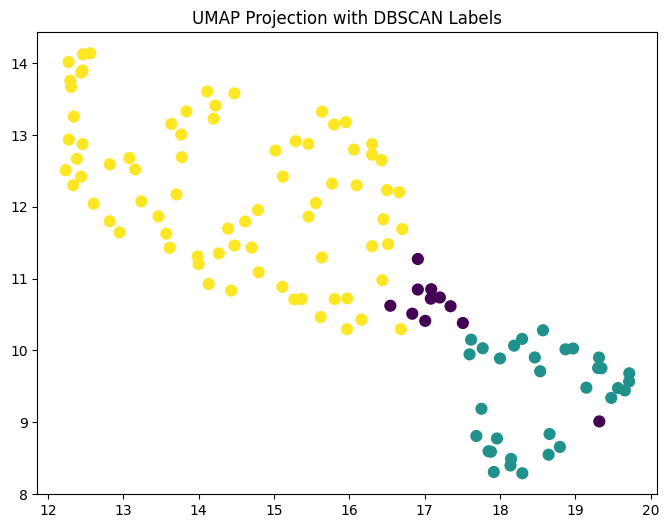

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(X_umap[:,0], X_umap[:,1],
            c=summary2["dbscan_cluster"], cmap="viridis", s=60)
plt.title("UMAP Projection with DBSCAN Labels")
plt.show()

In [38]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Filter to fixed Reynolds number
RE = 200000  # change to whichever Re you used
df_re = df[df["reynoldsNumber"] == RE].copy()

# Apply same feature engineering as your tool
# (your groupby aggregation here)
# Then scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# PCA
pca = PCA(n_components=3)
pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance:", pca.explained_variance_ratio_.sum())

# Factor loadings
loadings = pd.DataFrame(
    pca.components_,
    columns=features.columns,
    index=["PC1", "PC2", "PC3"]
)
print(loadings)

Explained variance ratio: [0.395813   0.26026512 0.18054548]
Total variance: 0.8366236003287344
     maxCamber  maxCamberXloc  maxThickness  reynoldsNumber    Cl_max  \
PC1   0.148880       0.171039     -0.109456        0.439512  0.481948   
PC2   0.540264       0.415871      0.447277       -0.079802  0.199681   
PC3   0.373359       0.531706     -0.485100       -0.253959 -0.140219   

       Cd_min  L_over_D_max  AoA_at_LD_max  
PC1 -0.457370      0.545603      -0.065460  
PC2  0.305027      0.008620       0.442440  
PC3  0.078421     -0.031843      -0.501248  


In [40]:
# Filter to fixed Reynolds number first
RE_FIXED = 200000
df_fixed = summary2[summary2["reynoldsNumber"] == RE_FIXED].copy()

# Define features WITHOUT Reynolds number since we've fixed it
feature_cols_fixed = [
    "maxCamber",
    "maxCamberXloc", 
    "maxThickness",
    "Cl_max",
    "Cd_min",
    "L_over_D_max",
    "AoA_at_LD_max"
]

features_fixed = df_fixed[feature_cols_fixed].dropna()

# Scale
scaler_fixed = StandardScaler()
X_scaled_fixed = scaler_fixed.fit_transform(features_fixed)

# PCA
pca_fixed = PCA(n_components=3)
pca_fixed.fit_transform(X_scaled_fixed)

print("Explained variance ratio:", pca_fixed.explained_variance_ratio_)
print(f"Total variance: {pca_fixed.explained_variance_ratio_.sum():.4f}")

# Factor loadings — force full width display
loadings_fixed = pd.DataFrame(
    pca_fixed.components_,
    columns=feature_cols_fixed,
    index=["PC1", "PC2", "PC3"]
)

# Set pandas to show all columns without wrapping
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)

print(loadings_fixed)

Explained variance ratio: [0.55208547 0.33411297 0.0651382 ]
Total variance: 0.9513
     maxCamber  maxCamberXloc  maxThickness  Cl_max  Cd_min  L_over_D_max  AoA_at_LD_max
PC1     0.4001         0.3089        0.3335  0.4846  0.3627        0.3240         0.4023
PC2    -0.3098        -0.4086        0.4767 -0.0699  0.4311       -0.4754         0.3051
PC3     0.1513         0.6048        0.2577 -0.3076  0.3253       -0.3309        -0.4848
